In [17]:
!pip install tensorflow keras numpy matplotlib

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
import os
from PIL import Image
import tensorflow_datasets as tfds
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install tensorflow-datasets

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached toml-0.10.2-py2.py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/5.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/5.3 MB ? eta -:--:--
   ------- -------------------------------- 1.0/5.3 MB 3.9 MB/s eta 0:00:02
   --------------- ------------------------ 2.1/5.3 MB 4.5 MB/s eta 0:00:01
   ----------------------- ---------------- 3.1/5.3 MB 4.6 MB/s eta 0:00:01
   --------------------------------- ------ 4.5/5.3 MB 5.1 MB/s eta 0:00:01
   ---------------------------------------- 5.3/5.3 MB 5.1 MB/s  0:00:01
Using cached toml-0.10.2-py2.py3-none-any.whl (16 kB)
  Created wheel for promise: filena


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
%pip install importlib_resources

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
ds_train, ds_test = tfds.load('emnist/letters', split=['train', 'test'], as_supervised=True)

def preprocess(image, label):
    image = tf.image.resize(image, [28, 28])  # Resize до 28x28
    image = tf.cast(image, tf.float32) / 255.0  # Нормализация
    label -= 1  # Метки начинаются с 1, делаем 0-based
    return image, label

ds_train = ds_train.map(preprocess)
ds_test = ds_test.map(preprocess)

ds_train_list = list(ds_train)
ds_test_list = list(ds_test)

c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Dl Completed...: 0 url [00:00, ? url/s]
Dl Completed...: 100%|██████████| 1/1 [02:15<00:00, 133.70s/ url]

Extraction completed...: 100%|██████████| 4/4 [00:00<00:00,  7.56 file/s] 


Dataset emnist downloaded and prepared to C:\Users\user\tensorflow_datasets\emnist\letters\3.1.0. Subsequent calls will reuse this data.


In [7]:
num_classes = 26

model = models.Sequential([
    layers.Conv2D(32, kernel_size=(3,3), activation='relu', input_shape=(28,28,1)),
    layers.MaxPooling2D(pool_size=(2,2)),
    layers.Conv2D(64, kernel_size=(3,3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2,2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 227,098 (887.10 KB)

 Trainable params: 227,098 (887.10 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(
    np.array([item[0].numpy() for item in ds_train_list]),
    np.array([item[1].numpy() for item in ds_train_list]),
    epochs=5,
    batch_size=64,
    validation_split=0.1
)
model.save('latin_letters_model.h5')

Epoch 1/5
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9490 - loss: 0.1391 - val_accuracy: 0.9328 - val_loss: 0.2252
Epoch 2/5
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9571 - loss: 0.1165 - val_accuracy: 0.9300 - val_loss: 0.2450
Epoch 3/5
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9608 - loss: 0.1025 - val_accuracy: 0.9279 - val_loss: 0.2507
Epoch 4/5
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9645 - loss: 0.0914 - val_accuracy: 0.9257 - val_loss: 0.2696
Epoch 5/5
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9673 - loss: 0.0830 - val_accuracy: 0.9285 - val_loss: 0.2686


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


IndexError: index 100 is out of bounds for axis 0 with size 100

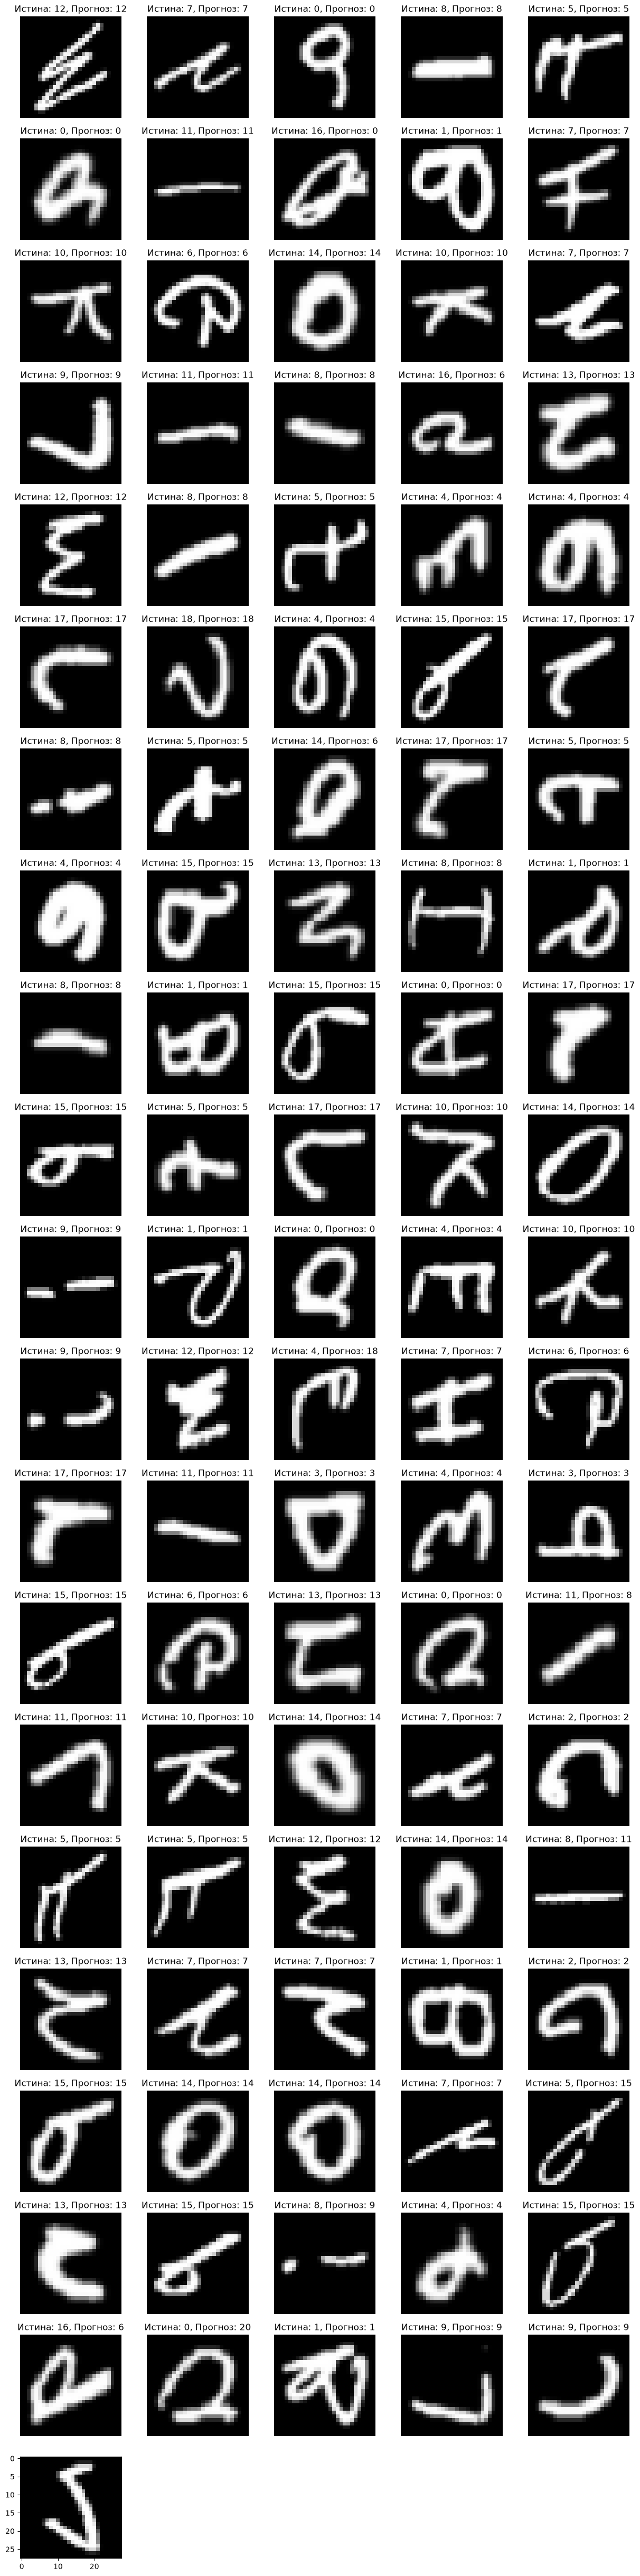

In [9]:
images_test = np.array([item[0].numpy() for item in ds_test_list])
labels_test = np.array([item[1].numpy() for item in ds_test_list])

predictions = model.predict(images_test[:100])
predicted_labels = np.argmax(predictions, axis=1)

num_images = len(images_test)
cols = 5
rows = (num_images + cols - 1) // cols

plt.figure(figsize=(15, rows * 3))
for i in range(num_images):
    plt.subplot(rows, cols, i + 1)
    plt.imshow(images_test[i].squeeze(), cmap='gray')
    plt.title(f'Истина: {labels_test[i]}, Прогноз: {predicted_labels[i]}')
    plt.axis('off')
plt.tight_layout()
plt.show()

accuracy = np.mean(predicted_labels == labels_test[:10])
print(f'Точность на первых 10 изображениях: {accuracy:.2%}')

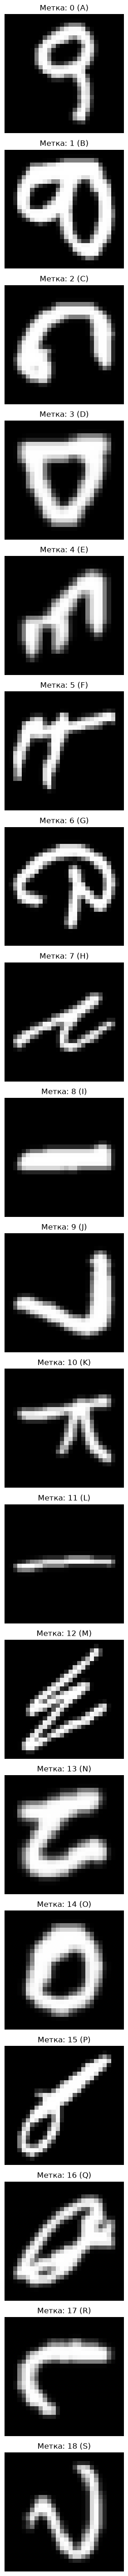

In [10]:
label_mapping = {
    0: 'A',
    1: 'B',
    2: 'C',
    3: 'D',
    4: 'E',
    5: 'F',
    6: 'G',
    7: 'H',
    8: 'I',
    9: 'J',
    10: 'K',
    11: 'L',
    12: 'M',
    13: 'N',
    14: 'O',
    15: 'P',
    16: 'Q',
    17: 'R',
    18: 'S',
    19: 'T',
    20: 'U',
    21: 'V',
    22: 'W',
    23: 'X',
    24: 'Y',
    25: 'Z'
}

unique_labels = np.unique(labels_test)

plt.figure(figsize=(15, 3 * len(unique_labels)))

for i, label in enumerate(unique_labels):
    index = np.where(labels_test == label)[0][0]
    img = images_test[index]
    plt.subplot(len(unique_labels), 1, i + 1)
    plt.imshow(img.squeeze(), cmap='gray')
    symbol = label_mapping.get(label, str(label))
    plt.title(f'Метка: {label} ({symbol})')
    plt.axis('off')

plt.tight_layout()
plt.show()








В предсказании символа используются латинские буквы (A-Z).
Формат изоброжения 28х28 пикселей





1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


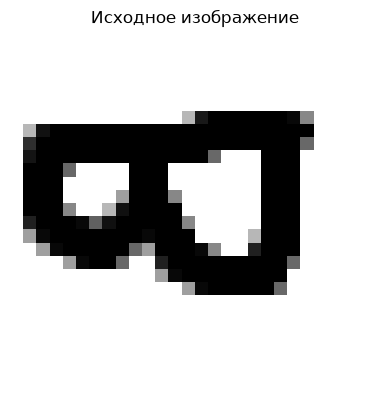

Индекс: 16
Предполагаемая буква: Q с уверенностью 0.97


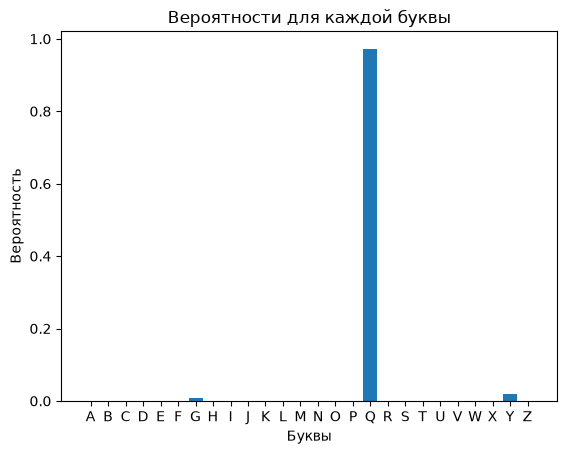

In [ ]:
model = load_model('latin_letters_model.h5')
labels = [chr(i + ord('A')) for i in range(26)]

print("\n\n\n\n\n\n\nВ предсказании символа используются латинские буквы (A-Z).\nФормат изоброжения 28х28 пикселей\n\n\n\n\n")

def predict_and_display(image_path):
    img = Image.open(image_path).convert('L')
    img = img.rotate(-90, expand=True)
    img = img.transpose(Image.FLIP_LEFT_RIGHT)
    img = img.resize((28, 28))s
    img_array = np.array(img).astype('float32') / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    img_array = np.expand_dims(img_array, axis=-1)

    # Предсказываем
    pred = model.predict(img_array)
    class_idx = np.argmax(pred)
    confidence = pred[0][class_idx]
    predicted_letter = chr(class_idx + ord('A'))


    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.title("Исходное изображение")
    plt.show()


    print(f"Индекс: {class_idx}")
    print(f"Предполагаемая буква: {predicted_letter} с уверенностью {confidence:.2f}")


    plt.bar(labels, pred[0])
    plt.xlabel('Буквы')
    plt.ylabel('Вероятность')
    plt.title('Вероятности для каждой буквы')
    plt.show()

image_path = r"C:\Users\user\Desktop\detects_ns\!symbols_ns\symbol.png"
predict_and_display(image_path)